# Climate-Sensitive Death Prediction

Goal: predict whether a death is climate-sensitive (`is_climate_sensitive`) from demographics, location, weather and satellite climate features.

Metric: `0.6 * F1 + 0.4 * ROC-AUC`

Workflow:
1. Load and merge the data
2. Clean and engineer features with one shared function
3. Explore the key patterns
4. Build one scikit-learn `Pipeline` (impute, scale, encode, model)
5. Evaluate, tune the decision threshold, check feature importance
6. Refit on all labelled data and write the submission

In [1]:
# 📚 Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 200)

In [2]:
# Settings
TARGET = "is_climate_sensitive"
SEED = 42

## 1. Load and merge the data

`climate_features.csv` holds extra climate columns per `ID`. Merge them into Train and Test. `deathdate` already exists in both files, so drop the duplicate copy first.

In [3]:
climate = pd.read_csv("climate_features.csv").drop(columns=["deathdate"])

train = pd.read_csv("Train.csv").merge(climate, on="ID", how="left")
test = pd.read_csv("Test.csv").merge(climate, on="ID", how="left")

# Remove duplicate rows (ignoring ID) from the training data
train = train.drop_duplicates(subset=[c for c in train.columns if c != "ID"])

print("Train:", train.shape, "| missing:", train.isna().sum().sum())
print("Test: ", test.shape, "| missing:", test.isna().sum().sum())
train.sample(5)

Train: (3144, 29) | missing: 0
Test:  (1030, 28) | missing: 0


,ID,zone,gender,deathdate,age,avg_temperature,max_temperature,min_temperature,precipitation,latitude,longitude,location,is_climate_sensitive,elevation,hot_days_30d,max_daily_rain_30d,ndvi_30d,ndvi_90d,rain_days_30d,rain_sum_30d,rain_sum_7d,rain_sum_90d,slope,tavg_30d,tavg_7d,tavg_90d,temp_range_mean_30d,tmax_30d,tmin_30d
1428,ID_0C67179E,Peri_urban,Female,2012-11-11,86.0,21.615600,25.228997,18.397966,2.040418,0.608396,33.482668,"Brac Uganda Iganga Regional Branch, Bikadho Ro...",0,1132,0,28.699108,0.58030,0.55340,21,257.071932,55.437835,547.906721,0.166667,21.414355,21.039376,21.487677,7.239165,28.409494,16.287439
1373,ID_9FFAA5F7,Rural,Female,2012-08-28,26.0,21.879469,26.119952,17.779673,0.248436,0.531798,33.538415,"Kabayingire Primary School, Namakunyu, Mayuge,...",1,1157,0,19.470522,0.68410,0.68410,11,91.009706,13.417387,270.144506,0.324049,20.959281,21.105136,20.893628,7.374891,26.373666,16.607538
1709,ID_281CBEE4,Peri_urban,Female,2013-12-15,0.0,20.584992,24.567244,17.893152,1.483707,0.608396,33.482668,"Brac Uganda Iganga Regional Branch, Bikadho Ro...",1,1132,0,22.463448,0.54835,0.56220,11,97.939671,33.695171,388.845329,0.166667,21.699342,21.073465,21.813075,7.218180,28.225977,17.536630
695,ID_5F92544B,Peri_urban,Male,2010-05-12,0.0,22.275781,25.935180,19.130073,0.286876,0.728530,33.468347,"Bulumwaki Church of Uganda Primary School, Kal...",1,1110,0,27.628201,0.77555,0.72775,23,258.919719,85.167603,557.028821,0.196194,22.073681,21.773421,22.563225,6.923549,27.877496,17.705316
2901,ID_7874DF5F,Rural,Female,2021-05-10,0.0,19.882374,22.251183,18.328640,4.674548,0.550000,33.450000,"Luyira, Mayuge, Uganda",1,1130,0,21.153048,0.66950,0.64685,21,214.058864,41.689165,433.173301,0.195107,21.725526,20.888869,22.578292,6.322705,27.364389,18.014459


### 1.1 Raw input files at a glance

Every file provided for the challenge, before any merging or cleaning.

In [4]:
raw_files = {
    "Train.csv": pd.read_csv("Train.csv"),
    "Test.csv": pd.read_csv("Test.csv"),
    "climate_features.csv": pd.read_csv("climate_features.csv"),
    "SampleSubmission.csv": pd.read_csv("SampleSubmission.csv"),
}

for name, df in raw_files.items():
    print(f"{name:<24} {df.shape[0]:>5} rows x {df.shape[1]:>2} cols  ->  {list(df.columns)}")

Train.csv                 3146 rows x 13 cols  ->  ['ID', 'zone', 'gender', 'deathdate', 'age', 'avg_temperature', 'max_temperature', 'min_temperature', 'precipitation', 'latitude', 'longitude', 'location', 'is_climate_sensitive']
Test.csv                  1030 rows x 12 cols  ->  ['ID', 'zone', 'gender', 'deathdate', 'age', 'avg_temperature', 'max_temperature', 'min_temperature', 'precipitation', 'latitude', 'longitude', 'location']
climate_features.csv      4176 rows x 18 cols  ->  ['ID', 'deathdate', 'elevation', 'hot_days_30d', 'max_daily_rain_30d', 'ndvi_30d', 'ndvi_90d', 'rain_days_30d', 'rain_sum_30d', 'rain_sum_7d', 'rain_sum_90d', 'slope', 'tavg_30d', 'tavg_7d', 'tavg_90d', 'temp_range_mean_30d', 'tmax_30d', 'tmin_30d']
SampleSubmission.csv      1030 rows x  3 cols  ->  ['ID', 'TargetF1', 'TargetRAUC']


### 1.2 Full column-by-column profile

One row per column: type, cardinality, missing values, and either numeric summary stats or the most frequent category. This covers every column in the merged train and test sets, not just the ones singled out later.

In [5]:
from IPython.display import display

def profile(df, name):
    rows = []
    for col in df.columns:
        s = df[col]
        row = {
            "column": col,
            "dtype": str(s.dtype),
            "n_unique": s.nunique(),
            "missing": int(s.isna().sum()),
            "missing_pct": round(100 * s.isna().mean(), 2),
        }
        if pd.api.types.is_numeric_dtype(s):
            row.update({
                "min": s.min(), "mean": round(s.mean(), 3),
                "median": s.median(), "max": s.max(),
                "std": round(s.std(), 3),
                "top_value": np.nan, "top_freq": np.nan,
            })
        else:
            counts = s.value_counts(dropna=True)
            row.update({
                "min": np.nan, "mean": np.nan, "median": np.nan,
                "max": np.nan, "std": np.nan,
                "top_value": counts.index[0] if len(counts) else None,
                "top_freq": int(counts.iloc[0]) if len(counts) else None,
            })
        rows.append(row)
    out = pd.DataFrame(rows).set_index("column")
    print(f"--- {name}: {df.shape[0]} rows x {df.shape[1]} cols ---")
    return out

display(profile(train, "train (merged, pre-cleaning)"))
display(profile(test, "test (merged, pre-cleaning)"))

--- train (merged, pre-cleaning): 3144 rows x 29 cols ---


,dtype,n_unique,missing,missing_pct,min,mean,median,max,std,top_value,top_freq
column,,,,,,,,,,,
ID,object,3144,0,0.0,NaN,NaN,NaN,NaN,NaN,ID_1FE951BD,1.0
zone,object,2,0,0.0,NaN,NaN,NaN,NaN,NaN,Rural,1971.0
gender,object,2,0,0.0,NaN,NaN,NaN,NaN,NaN,Male,1644.0
deathdate,object,2210,0,0.0,NaN,NaN,NaN,NaN,NaN,2008-11-25,6.0
age,float64,109,0,0.0,0.000000,24.259,3.000000,110.000000,31.433,NaN,NaN
avg_temperature,float64,2210,0,0.0,18.852803,22.066,21.931299,27.012223,1.095,NaN,NaN
max_temperature,float64,2210,0,0.0,20.884623,26.207,26.081829,34.080947,1.692,NaN,NaN
min_temperature,float64,2210,0,0.0,15.018778,18.514,18.510478,21.849602,0.892,NaN,NaN
precipitation,float64,2181,0,0.0,0.000000,1.520,1.034344,16.606523,1.622,NaN,NaN


--- test (merged, pre-cleaning): 1030 rows x 28 cols ---


,dtype,n_unique,missing,missing_pct,min,mean,median,max,std,top_value,top_freq
column,,,,,,,,,,,
ID,object,1030,0,0.0,NaN,NaN,NaN,NaN,NaN,ID_E760D84B,1.0
zone,object,2,0,0.0,NaN,NaN,NaN,NaN,NaN,Rural,785.0
gender,object,2,0,0.0,NaN,NaN,NaN,NaN,NaN,Male,531.0
deathdate,object,912,0,0.0,NaN,NaN,NaN,NaN,NaN,2021-06-24,3.0
age,float64,102,0,0.0,0.000000,23.922,3.000000,107.000000,31.124,NaN,NaN
avg_temperature,float64,912,0,0.0,18.954983,22.038,21.922381,26.981866,1.071,NaN,NaN
max_temperature,float64,912,0,0.0,21.359154,26.136,26.062903,34.080947,1.603,NaN,NaN
min_temperature,float64,912,0,0.0,15.018778,18.526,18.520424,20.936959,0.861,NaN,NaN
precipitation,float64,909,0,0.0,0.000112,1.614,1.023268,16.606523,1.819,NaN,NaN


## 2. Cleaning and feature engineering

One function prepares both Train and Test. This keeps the two datasets identical in structure and removes the copy-pasted test code from the original notebook.

- **Location**: fix typos, normalise spacing and casing, then extract the `region` (the segment before ", Uganda").
- **Date**: year, month and Uganda's rainy seasons (March to May, September to November).
- **Rainfall**: log precipitation, intensity and recent-vs-longer-term ratios.
- **Temperature**: daily range and short-term anomalies.
- **Vegetation**: NDVI change (drought or crop stress signal).
- **Age**: infant, under-5 and elderly flags, plus an under-5 × rainfall interaction.

In [6]:
RAINY_MONTHS = [3, 4, 5, 9, 10, 11]


def clean_location(s):
    return (
        s.str.replace("Propeer", "Proper", regex=False)
         .str.replace("Buwoya", "Buwaya", regex=False)
         .str.replace(", Eastern Region", "", regex=False)
         .str.replace(r",\s*,", ",", regex=True)
         .str.replace(r"\s+", " ", regex=True)
         .str.strip()
         .str.replace(r"\s*,\s*", ", ", regex=True)
         .str.title()
    )


def prepare(df):
    df = df.copy()

    # Location -> region
    df["location"] = clean_location(df["location"])
    df["region"] = df["location"].str.split(",").str[-2].str.strip()

    # Date
    date = pd.to_datetime(df["deathdate"])
    df["death_year"] = date.dt.year
    df["death_month"] = date.dt.month
    df["is_rainy_season"] = df["death_month"].isin(RAINY_MONTHS).astype(int)

    # Rainfall
    df["log_precipitation"] = np.log1p(df["precipitation"])
    df["rain_intensity_30d"] = df["rain_sum_30d"] / (df["rain_days_30d"] + 1)
    df["rain_recent_ratio"] = df["rain_sum_7d"] / (df["rain_sum_30d"] + 1)
    df["rain_30d_vs_90d"] = df["rain_sum_30d"] / (df["rain_sum_90d"] + 1)

    # Temperature
    df["temp_range"] = df["max_temperature"] - df["min_temperature"]
    df["temp_anomaly_7d"] = df["tavg_7d"] - df["tavg_90d"]
    df["heat_stress_30d"] = df["tmax_30d"] - df["tavg_90d"]

    # Vegetation
    df["ndvi_change"] = df["ndvi_30d"] - df["ndvi_90d"]

    # Age
    df["is_infant"] = (df["age"] == 0).astype(int)
    df["is_under5"] = (df["age"] < 5).astype(int)
    df["is_elderly"] = (df["age"] >= 60).astype(int)
    df["under5_x_rain30"] = df["is_under5"] * df["rain_sum_30d"]

    return df


train = prepare(train)
test = prepare(test)

train[["location", "region", "death_year", "death_month", "is_under5"]].head()

,location,region,death_year,death_month,is_under5
0,"Izimba, Iganga, Uganda",Iganga,2007,10,0
1,"Nawanzu, Iganga, Uganda",Iganga,2008,1,1
2,"Buluza, Iganga, Uganda",Iganga,2008,2,0
3,"Nawanzu, Iganga, Uganda",Iganga,2008,2,1
4,"Magada, Mbale City, Bugisa Sub-Region, Uganda",Bugisa Sub-Region,2008,2,0


## 3. Exploratory data analysis

Four views of the target: overall balance, and the climate-sensitive rate by age group, region and year.

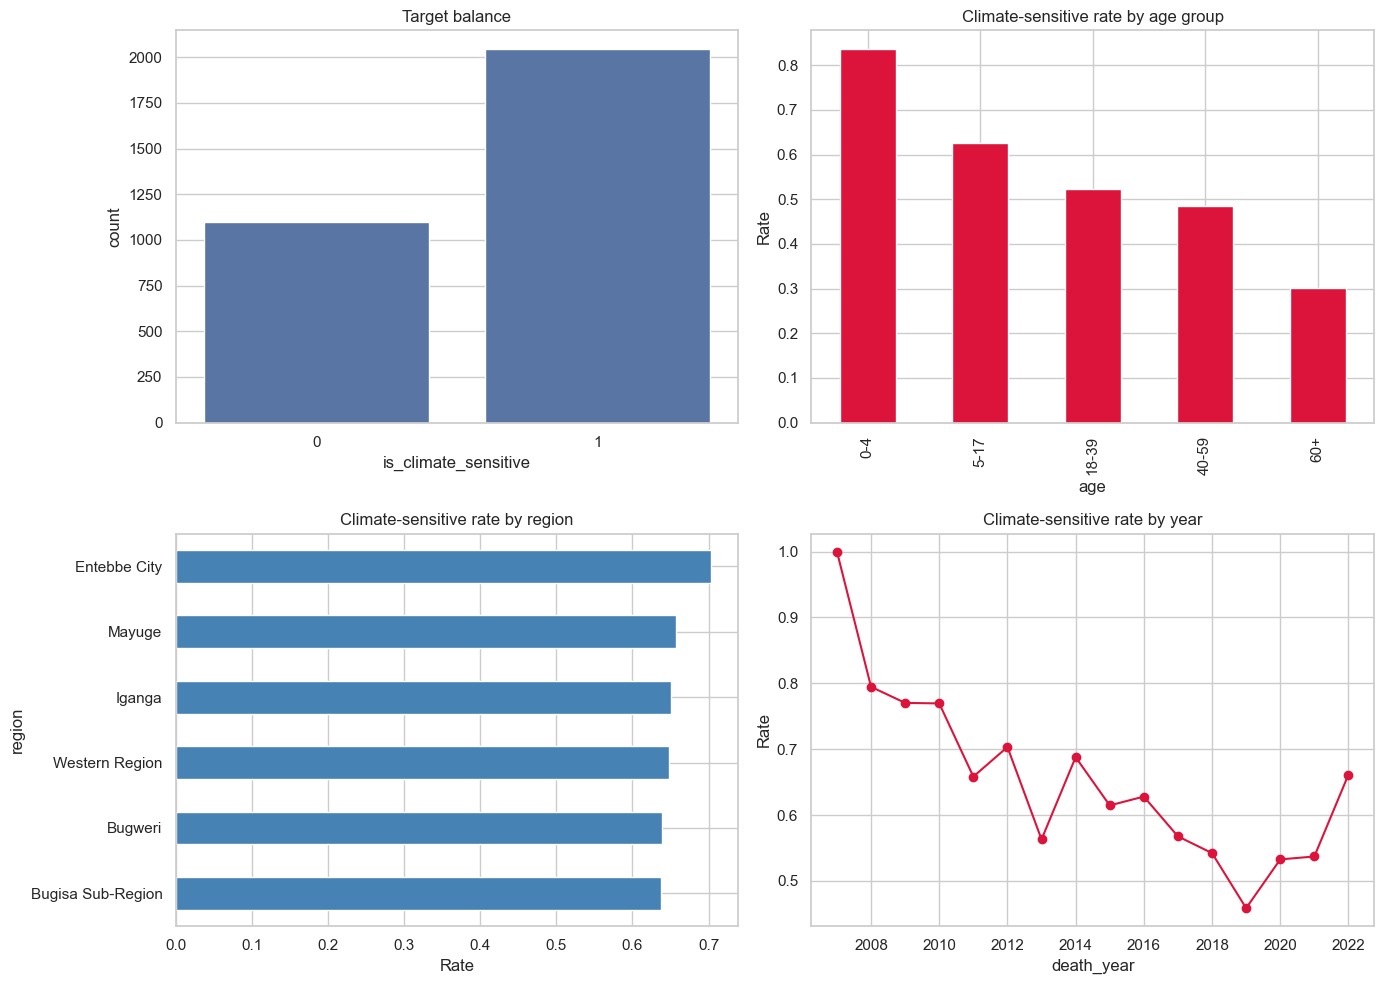

In [7]:
age_group = pd.cut(
    train["age"],
    bins=[-1, 4, 17, 39, 59, np.inf],
    labels=["0-4", "5-17", "18-39", "40-59", "60+"],
)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.countplot(x=TARGET, data=train, ax=axes[0, 0])
axes[0, 0].set_title("Target balance")

train.groupby(age_group, observed=True)[TARGET].mean().plot(
    kind="bar", ax=axes[0, 1], color="crimson"
)
axes[0, 1].set_title("Climate-sensitive rate by age group")
axes[0, 1].set_ylabel("Rate")

train.groupby("region")[TARGET].mean().sort_values().plot(
    kind="barh", ax=axes[1, 0], color="steelblue"
)
axes[1, 0].set_title("Climate-sensitive rate by region")
axes[1, 0].set_xlabel("Rate")

train.groupby("death_year")[TARGET].mean().plot(
    marker="o", ax=axes[1, 1], color="crimson"
)
axes[1, 1].set_title("Climate-sensitive rate by year")
axes[1, 1].set_ylabel("Rate")

plt.tight_layout()
plt.show()

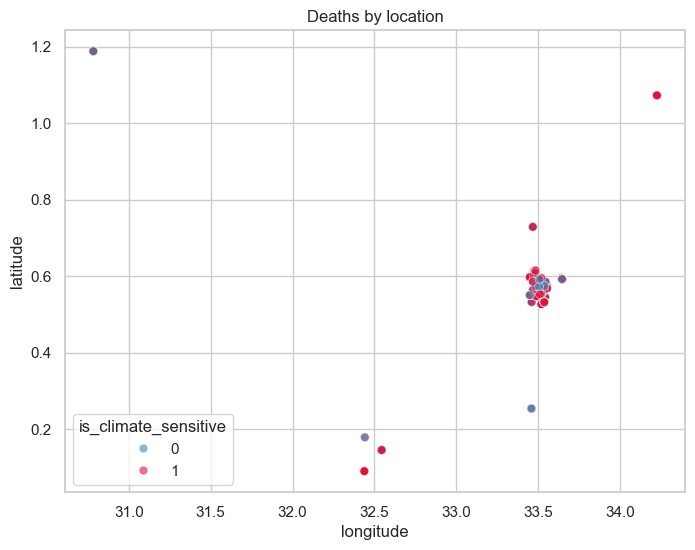

In [8]:
# Where the deaths happened, coloured by target
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=train, x="longitude", y="latitude", hue=TARGET,
    palette={0: "steelblue", 1: "crimson"}, alpha=0.6, s=40,
)
plt.title("Deaths by location")
plt.show()

### 3.1 Data quality checks

In [9]:
raw_train = pd.read_csv("Train.csv")
print("Train shape:", train.shape, "| Test shape:", test.shape)
print("Duplicate rows in raw Train.csv (excl. ID):",
      raw_train.duplicated(subset=[c for c in raw_train.columns if c != "ID"]).sum())
print("Missing values -> train:", train.isna().sum().sum(), "| test:", test.isna().sum().sum())
print("hot_days_30d unique values:", sorted(train["hot_days_30d"].unique()),
      "-> constant column, zero signal, already excluded from the model")
print()
print("Location cardinality -> train:", train["location"].nunique(), "| test:", test["location"].nunique())
unseen_loc = set(test["location"]) - set(train["location"])
print(f"Test locations never seen in train: {len(unseen_loc)} / {test['location'].nunique()}")
print("Test regions never seen in train:  ", sorted(set(test["region"]) - set(train["region"])))

Train shape: (3144, 45) | Test shape: (1030, 44)
Duplicate rows in raw Train.csv (excl. ID): 2
Missing values -> train: 0 | test: 0
hot_days_30d unique values: [0] -> constant column, zero signal, already excluded from the model

Location cardinality -> train: 37 | test: 11
Test locations never seen in train: 10 / 11
Test regions never seen in train:   ['Kalangala', 'Kamuli', 'Sembabule']


### 3.2 Age is the dominant signal

The target is far from independent of age, and the relationship is strongly non-linear (U-shaped rather than monotonic), so age needs to be modelled with enough flexibility (bins/splines, or a tree-based model) rather than as a single linear term.

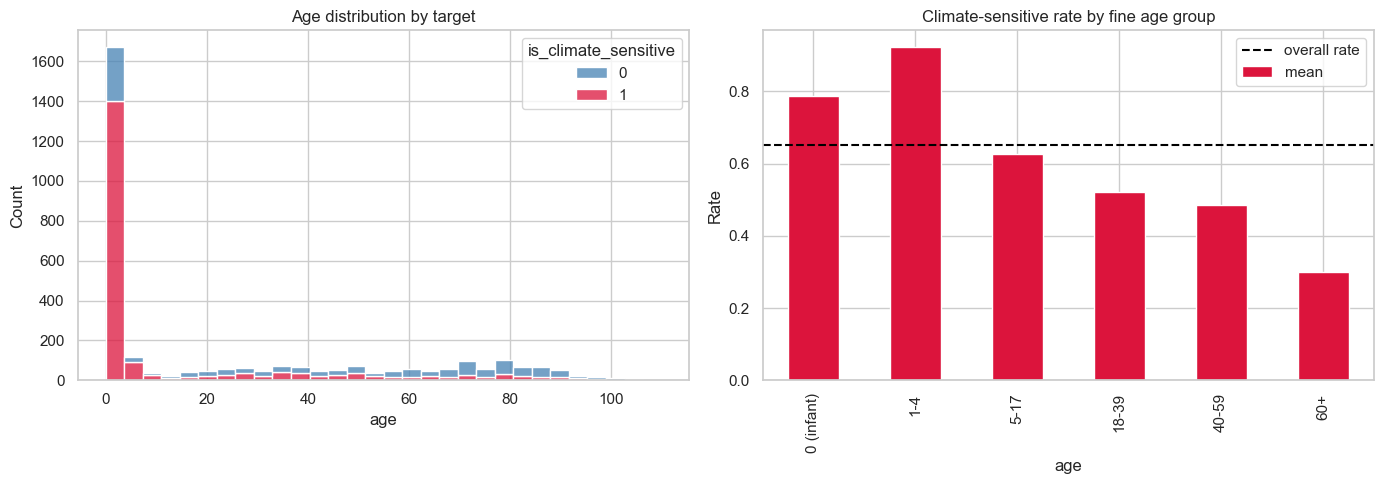

                mean  count
age                        
0 (infant)  0.787387   1110
1-4         0.922705    621
5-17        0.625899    139
18-39       0.522124    339
40-59       0.484429    289
60+         0.300310    646


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=train, x="age", hue=TARGET, bins=30, multiple="stack",
             palette={0: "steelblue", 1: "crimson"}, ax=axes[0])
axes[0].set_title("Age distribution by target")

age_bins = pd.cut(train["age"], bins=[-1, 0, 4, 17, 39, 59, np.inf],
                   labels=["0 (infant)", "1-4", "5-17", "18-39", "40-59", "60+"])
rate_by_age = train.groupby(age_bins, observed=True)[TARGET].agg(["mean", "count"])
rate_by_age["mean"].plot(kind="bar", ax=axes[1], color="crimson")
axes[1].axhline(train[TARGET].mean(), color="black", linestyle="--", label="overall rate")
axes[1].set_title("Climate-sensitive rate by fine age group")
axes[1].set_ylabel("Rate")
axes[1].legend()
plt.tight_layout()
plt.show()

print(rate_by_age)

### 3.3 Ranking every numeric feature by correlation with the target

Point-biserial correlation (equivalent to Pearson correlation against the 0/1 target) for every numeric column, including the engineered features.

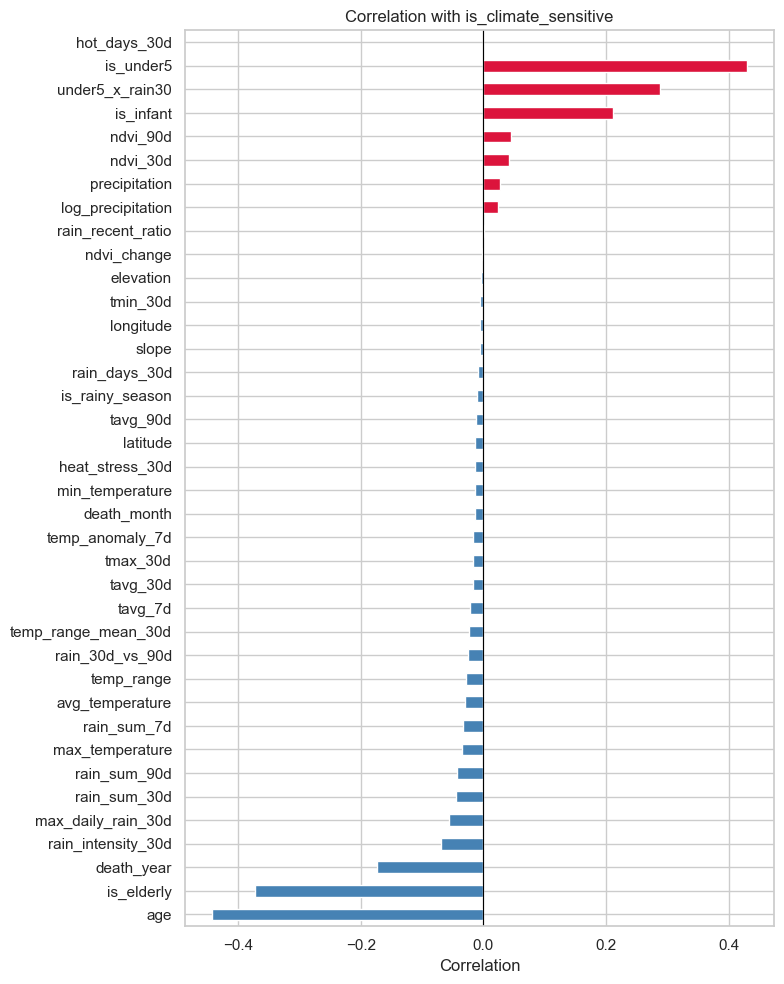

age                   -0.443
is_under5              0.431
is_elderly            -0.373
under5_x_rain30        0.288
is_infant              0.212
death_year            -0.174
rain_intensity_30d    -0.069
max_daily_rain_30d    -0.057
ndvi_90d               0.045
rain_sum_30d          -0.044
rain_sum_90d          -0.043
ndvi_30d               0.041
max_temperature       -0.036
rain_sum_7d           -0.033
avg_temperature       -0.030
temp_range            -0.028
precipitation          0.028
rain_30d_vs_90d       -0.025
temp_range_mean_30d   -0.023
log_precipitation      0.023
tavg_7d               -0.021
tavg_30d              -0.018
tmax_30d              -0.018
temp_anomaly_7d       -0.016
death_month           -0.014
min_temperature       -0.014
heat_stress_30d       -0.014
latitude              -0.013
tavg_90d              -0.013
is_rainy_season       -0.011
rain_days_30d         -0.008
slope                 -0.006
longitude             -0.005
tmin_30d              -0.005
elevation     

In [11]:
num_cols = [c for c in train.select_dtypes(include=[np.number]).columns if c != TARGET]
corr = train[num_cols + [TARGET]].corr()[TARGET].drop(TARGET).sort_values()

plt.figure(figsize=(8, 10))
colors = ["crimson" if v > 0 else "steelblue" for v in corr.values]
corr.plot(kind="barh", color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Correlation with is_climate_sensitive")
plt.xlabel("Correlation")
plt.tight_layout()
plt.show()

print(corr.reindex(corr.abs().sort_values(ascending=False).index).round(3))

### 3.4 Categorical features: zone, gender, region

Chi-square test of independence for each categorical feature against the target, plus the climate-sensitive rate per category.

In [12]:
from scipy import stats

for col in ["zone", "gender", "region"]:
    ct = pd.crosstab(train[col], train[TARGET])
    chi2, p, _, _ = stats.chi2_contingency(ct)
    rates = train.groupby(col)[TARGET].agg(["mean", "count"]).sort_values("mean")
    print(f"--- {col} (chi2 p-value = {p:.4f}) ---")
    print(rates, "\n")

# gender's effect is concentrated in working-age adults, not infants/elderly
age_grp = np.where(train["age"] < 5, "under5", np.where(train["age"] >= 60, "60+", "5-59"))
print("Climate-sensitive rate by gender x age group:")
print(train.groupby([pd.Series(age_grp, index=train.index), "gender"])[TARGET].mean().unstack())

--- zone (chi2 p-value = 0.3750) ---
                mean  count
zone                       
Peri_urban  0.640239   1173
Rural       0.656520   1971 

--- gender (chi2 p-value = 0.0210) ---
            mean  count
gender                 
Male    0.631387   1644
Female  0.671333   1500 

--- region (chi2 p-value = 0.9642) ---
                       mean  count
region                            
Bugisa Sub-Region  0.636943    157
Bugweri            0.638191    199
Western Region     0.648438    128
Iganga             0.650556   2338
Mayuge             0.656716    268
Entebbe City       0.703704     54 

Climate-sensitive rate by gender x age group:
gender    Female      Male
5-59    0.620482  0.455172
60+     0.289634  0.311321
under5  0.840476  0.831650


### 3.5 Climate features are highly redundant with each other

The temperature family and the rainfall family are each internally collinear (r up to ~0.9), so most windows (7d/30d/90d) carry overlapping information rather than independent signal.

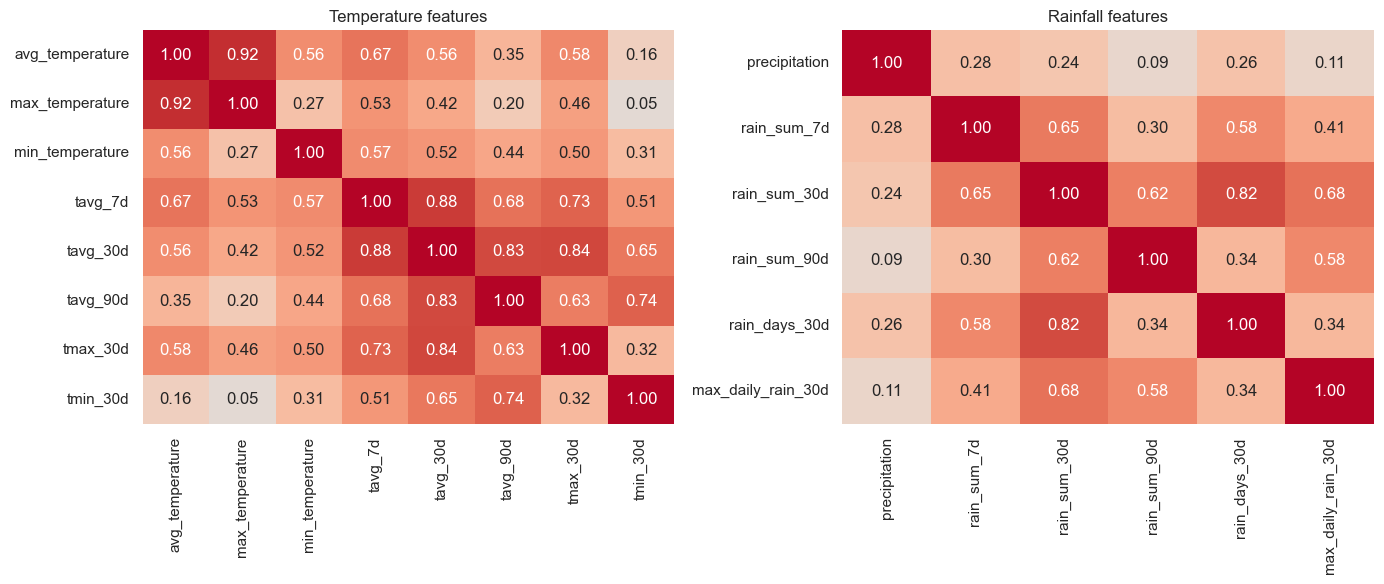

In [13]:
temp_cols = ["avg_temperature", "max_temperature", "min_temperature",
             "tavg_7d", "tavg_30d", "tavg_90d", "tmax_30d", "tmin_30d"]
rain_cols = ["precipitation", "rain_sum_7d", "rain_sum_30d", "rain_sum_90d",
             "rain_days_30d", "max_daily_rain_30d"]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.heatmap(train[temp_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm",
            center=0, ax=axes[0], cbar=False)
axes[0].set_title("Temperature features")
sns.heatmap(train[rain_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm",
            center=0, ax=axes[1], cbar=False)
axes[1].set_title("Rainfall features")
plt.tight_layout()
plt.show()

### 3.6 Train vs. test: does the geography generalize?

Kolmogorov-Smirnov two-sample test per numeric feature. A large KS statistic means train and test are drawn from visibly different distributions for that column -- a warning sign for features the model might lean on but that won't transfer to the test locations.

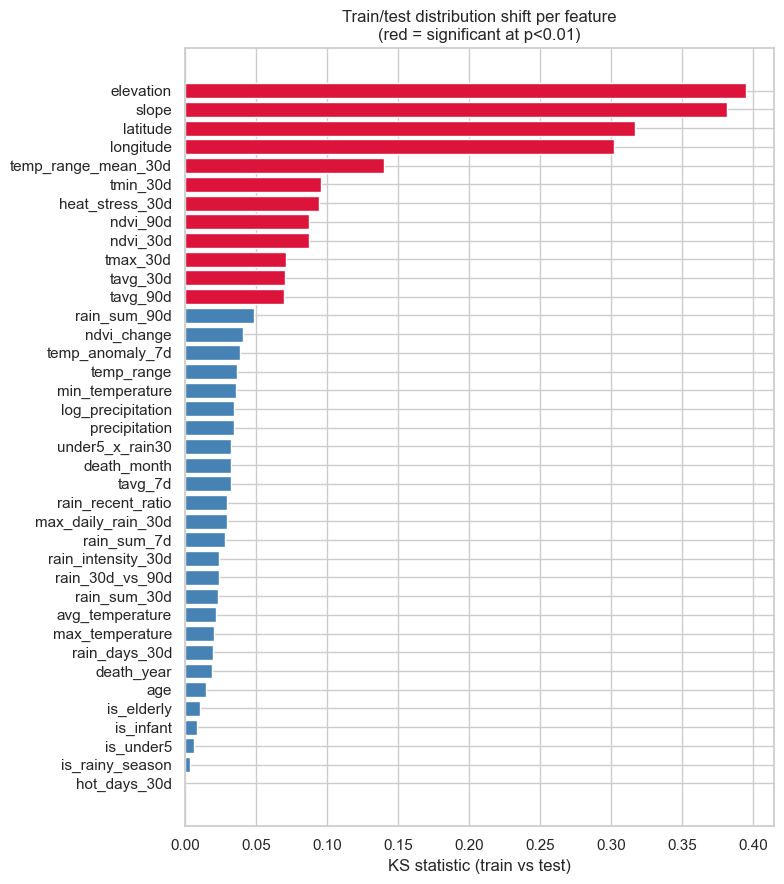

            feature  ks_stat          ks_p
          elevation 0.395136 6.099375e-109
              slope 0.381733 1.680968e-101
           latitude 0.316677  2.226788e-69
          longitude 0.302306  3.663866e-63
temp_range_mean_30d 0.139992  1.003972e-13
           tmin_30d 0.095485  1.302842e-06
    heat_stress_30d 0.094610  1.689512e-06
           ndvi_90d 0.087389  1.313061e-05


In [14]:
shift_rows = []
for c in num_cols:
    if c in test.columns:
        ks_stat, ks_p = stats.ks_2samp(train[c].dropna(), test[c].dropna())
        shift_rows.append((c, ks_stat, ks_p))
shift = pd.DataFrame(shift_rows, columns=["feature", "ks_stat", "ks_p"]).sort_values("ks_stat", ascending=False)

plt.figure(figsize=(8, 9))
plt.barh(shift["feature"], shift["ks_stat"],
         color=["crimson" if p < 0.01 else "steelblue" for p in shift["ks_p"]])
plt.xlabel("KS statistic (train vs test)")
plt.title("Train/test distribution shift per feature\n(red = significant at p<0.01)")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

print(shift.head(8).to_string(index=False))

### Key takeaways from the data

- **Age dominates, and peaks in toddlers, not infants.** Age is the single strongest predictor (corr ≈ -0.44). The rate climbs from 79% at age 0 to a peak of **92% at ages 1-4**, then falls through childhood to ~30% for 60+, against an overall base rate of ~65%. The dip at age 0 relative to 1-4 suggests infant deaths have a different (less climate-driven) cause mix than toddler deaths -- worth encoding as a non-linear age feature (bins/splines or a tree split) rather than a linear term.
- **Individual climate variables are weak in isolation.** Every raw or engineered climate feature (temperature, rainfall, NDVI, elevation, slope) has |corr| < 0.06 with the target on its own. That does not mean they are useless -- the signal may live in *interactions* (e.g. heat + infancy) rather than main effects -- but no single climate column carries the label by itself.
- **`hot_days_30d` is dead.** It is a constant 0 for every row in both train and test -- correctly excluded from the model already.
- **Gender has a mild, age-dependent effect.** Marginal on its own (p ≈ 0.02), but within the 5-59 age band the climate-sensitive rate is much higher for women than men -- a candidate interaction term.
- **Geography does not generalize.** Elevation, slope, latitude and longitude all show large train/test distribution shift, and most test locations (and half the test regions) never appear in train at all. `region`/`location` features risk overfitting to places the model will never see again -- prefer the weather variables (which are stable across train/test) over place identity.
- **Climate features are highly collinear.** The temperature family and the rainfall family each cluster at r = 0.6-0.9 with each other, so the 7d/30d/90d windows mostly duplicate information rather than adding independent signal.
- Two fully-duplicate rows (excluding ID) exist in the raw training data and are already dropped during the merge step.

### 3.7 Applying the fixes: a reproducible data-quality refinement

Turning the findings above into concrete changes, all in one place so the effect on model performance can be measured directly:

1. Drop dead (`hot_days_30d`) and non-generalizing geo columns (`location`, `region`, `elevation`, `slope`, `latitude`, `longitude`).
2. Encode `age` as the non-linear bands the data actually shows.
3. Add the gender x working-age interaction found in 3.4.
4. Compress the collinear temperature and rainfall families into PCA components.
5. Re-check for near-duplicate records beyond the exact duplicates already removed.

In [15]:
from sklearn.decomposition import PCA
from IPython.display import display

# ---------------------------------------------------------------------------
# 0. Near-duplicate check, beyond the 2 exact duplicates already dropped in 1.
# ---------------------------------------------------------------------------
DUP_KEY = ["deathdate", "location", "age", "gender", "avg_temperature"]
near_dup_mask = train.duplicated(subset=DUP_KEY, keep=False)
print(f"Near-duplicate records (same date/location/age/gender/temp): {near_dup_mask.sum()}")
if near_dup_mask.any():
    display(train.loc[near_dup_mask, DUP_KEY + [TARGET]].sort_values(DUP_KEY))
    train = train.drop_duplicates(subset=DUP_KEY, keep="first")
    print("-> dropped extras, kept first occurrence. New train shape:", train.shape)

# ---------------------------------------------------------------------------
# 1. Drop dead / non-generalizing geo features (EDA 3.1 and 3.6):
#    hot_days_30d is constant; location/region/elevation/slope/lat/long show
#    heavy train-test distribution shift and most test locations are unseen
#    in train, so they cannot be relied on to generalize.
# ---------------------------------------------------------------------------
UNRELIABLE_GEO = ["location", "region", "elevation", "slope", "latitude", "longitude"]
DEAD_COLS = ["hot_days_30d"]

def drop_unreliable(df):
    return df.drop(columns=[c for c in UNRELIABLE_GEO + DEAD_COLS if c in df.columns])

train_r = drop_unreliable(train)
test_r = drop_unreliable(test)

# ---------------------------------------------------------------------------
# 2. Non-linear age encoding (EDA 3.2): the climate-sensitive rate peaks at
#    ages 1-4 (92%), not at age 0 (79%), then falls steadily to 30% at 60+ --
#    a pattern a single linear "age" term cannot represent.
# ---------------------------------------------------------------------------
AGE_BINS = [-1, 0, 4, 17, 39, 59, np.inf]
AGE_LABELS = ["0", "1-4", "5-17", "18-39", "40-59", "60+"]

for df in (train_r, test_r):
    df["age_band"] = pd.cut(df["age"], bins=AGE_BINS, labels=AGE_LABELS).astype(str)

# ---------------------------------------------------------------------------
# 3. Gender x working-age interaction (EDA 3.4): within the 5-59 age band,
#    women are climate-sensitive 62% of the time vs. 46% for men -- an
#    effect invisible to gender or age alone.
# ---------------------------------------------------------------------------
for df in (train_r, test_r):
    working_age = df["age"].between(5, 59)
    df["female_working_age"] = ((df["gender"] == "Female") & working_age).astype(int)

# ---------------------------------------------------------------------------
# 4. Collapse collinear climate families into PCA components (EDA 3.5): the
#    temperature family and rainfall family are each internally collinear
#    (r up to ~0.9), so the raw 7d/30d/90d windows mostly duplicate the same
#    information. 3 components per family keeps ~85-88% of that variance in
#    a fifth of the columns.
# ---------------------------------------------------------------------------
TEMP_FAMILY = ["avg_temperature", "max_temperature", "min_temperature",
               "tavg_7d", "tavg_30d", "tavg_90d", "tmax_30d", "tmin_30d"]
RAIN_FAMILY = ["precipitation", "rain_sum_7d", "rain_sum_30d", "rain_sum_90d",
               "rain_days_30d", "max_daily_rain_30d"]

def compress_family(train_df, test_df, cols, prefix, n_components=3):
    scaler = StandardScaler().fit(train_df[cols])
    pca = PCA(n_components=n_components, random_state=SEED).fit(scaler.transform(train_df[cols]))
    for df in (train_df, test_df):
        comps = pca.transform(scaler.transform(df[cols]))
        for i in range(n_components):
            df[f"{prefix}_pc{i + 1}"] = comps[:, i]
    explained = pca.explained_variance_ratio_
    print(f"{prefix}_pc1..{n_components}: explain {explained.sum():.1%} "
          f"of variance {explained.round(3).tolist()}")

compress_family(train_r, test_r, TEMP_FAMILY, "temp")
compress_family(train_r, test_r, RAIN_FAMILY, "rain")

train_r = train_r.drop(columns=TEMP_FAMILY + RAIN_FAMILY)
test_r = test_r.drop(columns=[c for c in TEMP_FAMILY + RAIN_FAMILY if c in test_r.columns])

# ---------------------------------------------------------------------------
# Swap the refined frames in for the rest of the notebook
# ---------------------------------------------------------------------------
train, test = train_r, test_r

print()
print("Refined train:", train.shape, "| refined test:", test.shape)
print("Dropped:", UNRELIABLE_GEO + DEAD_COLS + TEMP_FAMILY + RAIN_FAMILY)
print("Added:  ", ["age_band", "female_working_age", "temp_pc1..3", "rain_pc1..3"])
train.head()

Near-duplicate records (same date/location/age/gender/temp): 0
temp_pc1..3: explain 87.6% of variance [0.604, 0.19, 0.082]
rain_pc1..3: explain 84.4% of variance [0.542, 0.177, 0.125]

Refined train: (3144, 32) | refined test: (1030, 31)
Dropped: ['location', 'region', 'elevation', 'slope', 'latitude', 'longitude', 'hot_days_30d', 'avg_temperature', 'max_temperature', 'min_temperature', 'tavg_7d', 'tavg_30d', 'tavg_90d', 'tmax_30d', 'tmin_30d', 'precipitation', 'rain_sum_7d', 'rain_sum_30d', 'rain_sum_90d', 'rain_days_30d', 'max_daily_rain_30d']
Added:   ['age_band', 'female_working_age', 'temp_pc1..3', 'rain_pc1..3']


,ID,zone,gender,deathdate,age,is_climate_sensitive,ndvi_30d,ndvi_90d,temp_range_mean_30d,death_year,death_month,is_rainy_season,log_precipitation,rain_intensity_30d,rain_recent_ratio,rain_30d_vs_90d,temp_range,temp_anomaly_7d,heat_stress_30d,ndvi_change,is_infant,is_under5,is_elderly,under5_x_rain30,age_band,female_working_age,temp_pc1,temp_pc2,temp_pc3,rain_pc1,rain_pc2,rain_pc3
0,ID_1FE951BD,Rural,Male,2007-10-02,30.0,1,0.72205,0.72910,7.897970,2007,10,1,0.668650,9.224424,0.161230,0.414343,7.117375,0.968588,6.564792,-0.00705,0,0,0,0.000000,18-39,0,-1.600927,0.408894,0.517003,0.878473,-0.248489,-0.581125
1,ID_5927A443,Rural,Male,2008-01-05,2.0,1,0.60815,0.66985,8.735769,2008,1,0,0.051978,8.985745,0.000000,0.266798,10.334814,1.029252,7.259803,-0.06170,0,1,0,71.885960,1-4,0,1.544342,2.684544,0.013077,-1.941547,-0.767084,-0.009530
2,ID_C4E67025,Rural,Female,2008-02-14,31.0,1,0.59290,0.61335,7.694241,2008,2,0,0.086498,5.149780,0.329564,0.444893,8.633080,-0.663055,6.863290,-0.02045,0,0,0,0.000000,18-39,1,0.175769,0.114275,-0.584751,-0.117067,0.355802,-1.679257
3,ID_44DC5CE9,Rural,Female,2008-02-15,1.0,1,0.59290,0.61335,7.718027,2008,2,0,0.252170,4.926226,0.292301,0.427678,9.101181,-0.537828,6.852188,-0.02045,0,1,0,98.524518,1-4,0,1.044849,0.988360,-0.056936,-0.404388,0.362795,-1.440774
4,ID_33C677BB,Rural,Female,2008-02-15,69.0,0,0.53380,0.71580,10.152887,2008,2,0,0.252170,6.002162,0.302229,0.449170,9.101181,-0.368638,7.790339,-0.18200,0,0,1,0.000000,60+,0,-2.584072,4.355593,1.385079,-1.249654,0.296519,-1.080020


## 4. Features and preprocessing pipeline

- **Dropped**: `ID`, `deathdate` (replaced by year and month), `location` (near-unique free text, replaced by `region`) and `hot_days_30d` (constant, carries no signal).
- **Numeric**: median imputation, then standard scaling (unnecessary for Random Forest, kept so the pipeline works unchanged if the classifier is swapped back).
- **Categorical**: most-frequent imputation, then one-hot encoding. `handle_unknown="ignore"` covers regions seen only in Test.

The pipeline fits all preprocessing on training data only, so no information leaks from validation or test rows.

In [16]:
DROP_COLS = ["ID", "deathdate", TARGET]
CAT_COLS = ["gender", "zone", "age_band"]

X = train.drop(columns=DROP_COLS)
y = train[TARGET]
NUM_COLS = [c for c in X.columns if c not in CAT_COLS]

print(f"{len(NUM_COLS)} numeric + {len(CAT_COLS)} categorical features")
print("Target balance:", y.value_counts(normalize=True).round(3).to_dict())

26 numeric + 3 categorical features
Target balance: {1: 0.65, 0: 0.35}


In [17]:
numeric_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])

categorical_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("encode", OneHotEncoder(handle_unknown="ignore")),
])

preprocess = ColumnTransformer([
    ("num", numeric_pipe, NUM_COLS),
    ("cat", categorical_pipe, CAT_COLS),
])

model = Pipeline([
    ("preprocess", preprocess),
    ("clf", RandomForestClassifier(
        n_estimators=300, class_weight="balanced", random_state=SEED, n_jobs=-1
    )),
])

model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocess', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contai

## 5. Train and evaluate

80/20 stratified split. `evaluate()` prints F1, ROC-AUC, the combined competition score, a classification report and a confusion matrix.

Validation (threshold = 0.50)
  F1:               0.8174
  ROC-AUC:          0.8184
  Combined (60/40): 0.8178

              precision    recall  f1-score   support

           0       0.67      0.58      0.62       220
           1       0.79      0.85      0.82       409

    accuracy                           0.75       629
   macro avg       0.73      0.71      0.72       629
weighted avg       0.75      0.75      0.75       629



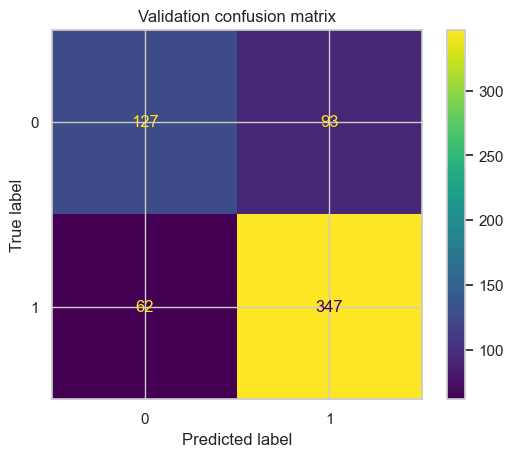

In [18]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)

model.fit(X_train, y_train)
val_proba = model.predict_proba(X_val)[:, 1]


def evaluate(y_true, proba, threshold=0.5, title="Validation"):
    pred = (proba >= threshold).astype(int)
    f1 = f1_score(y_true, pred)
    auc = roc_auc_score(y_true, proba)
    print(f"{title} (threshold = {threshold:.2f})")
    print(f"  F1:               {f1:.4f}")
    print(f"  ROC-AUC:          {auc:.4f}")
    print(f"  Combined (60/40): {0.6 * f1 + 0.4 * auc:.4f}\n")
    print(classification_report(y_true, pred))
    ConfusionMatrixDisplay(confusion_matrix(y_true, pred)).plot()
    plt.title(f"{title} confusion matrix")
    plt.show()


evaluate(y_val, val_proba)

### Tune the decision threshold

`class_weight="balanced"` pushes predictions toward the minority class, so 0.5 is rarely the best cut-off for F1. ROC-AUC ignores the threshold, so tuning the threshold only moves the F1 part of the score.

The threshold comes from the validation set. Treat the tuned score as slightly optimistic.

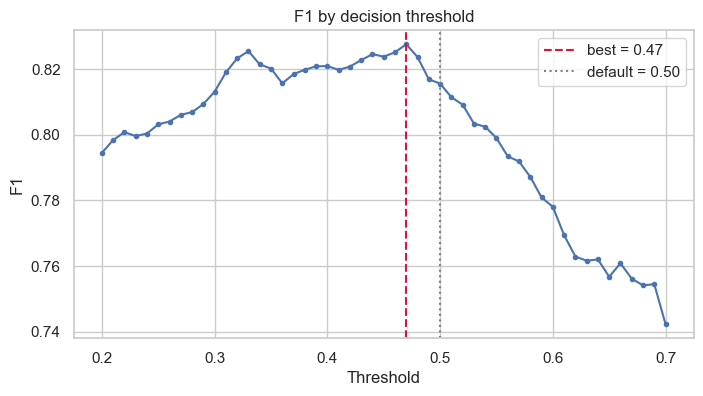

Validation, tuned (threshold = 0.47)
  F1:               0.8276
  ROC-AUC:          0.8184
  Combined (60/40): 0.8239

              precision    recall  f1-score   support

           0       0.71      0.54      0.61       220
           1       0.78      0.88      0.83       409

    accuracy                           0.76       629
   macro avg       0.74      0.71      0.72       629
weighted avg       0.76      0.76      0.75       629



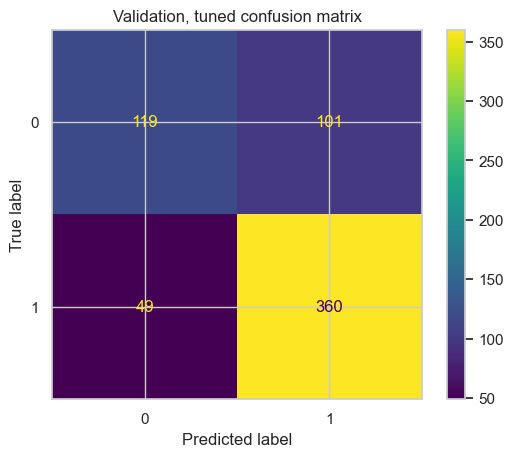

In [19]:
thresholds = np.arange(0.20, 0.71, 0.01)
f1_scores = [f1_score(y_val, (val_proba >= t).astype(int)) for t in thresholds]
best_threshold = thresholds[int(np.argmax(f1_scores))]

plt.figure(figsize=(8, 4))
plt.plot(thresholds, f1_scores, marker=".")
plt.axvline(best_threshold, color="crimson", linestyle="--", label=f"best = {best_threshold:.2f}")
plt.axvline(0.5, color="grey", linestyle=":", label="default = 0.50")
plt.xlabel("Threshold")
plt.ylabel("F1")
plt.title("F1 by decision threshold")
plt.legend()
plt.show()

evaluate(y_val, val_proba, threshold=best_threshold, title="Validation, tuned")

## 6. Feature importance

Two views, combined into one ranking:
- **Permutation importance**: shuffles one raw column at a time and measures the drop in validation ROC-AUC. Model-agnostic, but slower and noisier for correlated features.
- **Random Forest importance**: mean decrease in impurity across all trees, free from the fitted model. Biased toward high-cardinality features, and correlated features can split importance between them.

Each categorical column's one-hot dummies are summed back into a single score so it lines up with the raw column used by permutation importance. Both scores are scaled to 0-1 by their own max and averaged into a `combined_score`, so neither method dominates just because it happens to produce larger numbers.

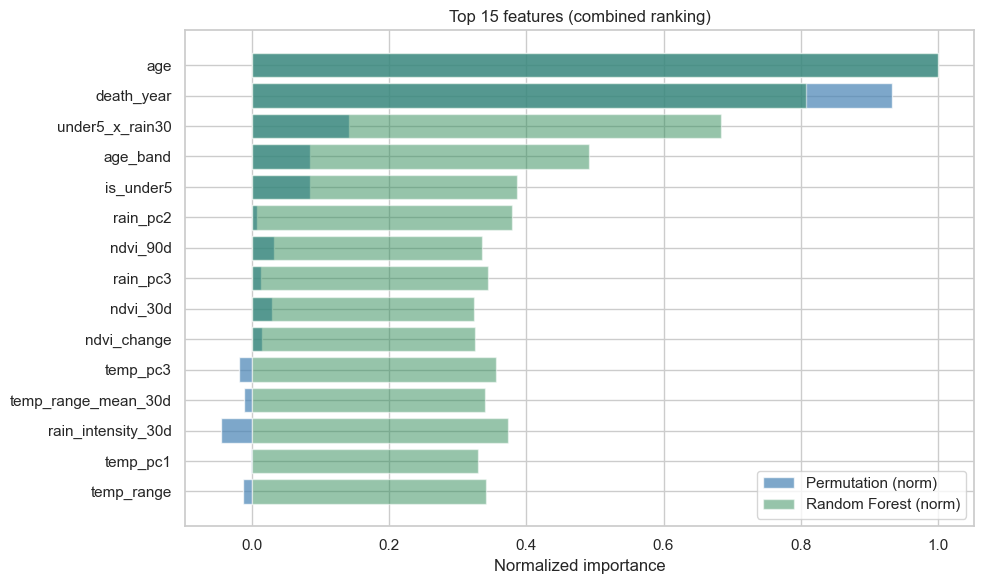

,feature,perm_importance,rf_importance,perm_norm,rf_norm,combined_score
0,age,0.056093,0.101151,1.000000,1.000000,1.000000
1,death_year,0.052358,0.081629,0.933419,0.807001,0.870210
2,under5_x_rain30,0.007998,0.069129,0.142583,0.683420,0.413001
3,age_band,0.004773,0.049654,0.085086,0.490894,0.287990
4,is_under5,0.004784,0.039120,0.085284,0.386745,0.236015
5,rain_pc2,0.000437,0.038380,0.007796,0.379434,0.193615
6,ndvi_90d,0.001850,0.034009,0.032978,0.336220,0.184599
7,rain_pc3,0.000802,0.034806,0.014305,0.344098,0.179202
8,ndvi_30d,0.001628,0.032828,0.029016,0.324543,0.176779
9,ndvi_change,0.000889,0.032902,0.015840,0.325275,0.170558


In [20]:
# Permutation importance (raw columns, drop in ROC-AUC)
perm = permutation_importance(
    model, X_val, y_val,
    scoring="roc_auc", n_repeats=10, random_state=SEED, n_jobs=-1,
)
perm_importance = pd.DataFrame({
    "feature": X_val.columns,
    "perm_importance": perm.importances_mean,
})

# Random Forest importance (mean decrease in impurity), summed back from
# one-hot dummies to the raw categorical column so it lines up with perm_importance
def base_feature(name):
    name = name.split("__", 1)[1]
    for c in CAT_COLS:
        if name.startswith(c + "_"):
            return c
    return name

feature_names = model.named_steps["preprocess"].get_feature_names_out()
rf_raw = pd.DataFrame({
    "feature": [base_feature(f) for f in feature_names],
    "importance": model.named_steps["clf"].feature_importances_,
})
rf_importance = rf_raw.groupby("feature", as_index=False)["importance"].sum()
rf_importance.columns = ["feature", "rf_importance"]

# Combine: scale each method 0-1 by its own max, then average
importance = perm_importance.merge(rf_importance, on="feature", how="outer").fillna(0)
importance["perm_norm"] = importance["perm_importance"] / importance["perm_importance"].max()
importance["rf_norm"] = importance["rf_importance"] / importance["rf_importance"].max()
importance["combined_score"] = (importance["perm_norm"] + importance["rf_norm"]) / 2
importance = importance.sort_values("combined_score", ascending=False).reset_index(drop=True)

top = importance.head(15).iloc[::-1]
plt.figure(figsize=(10, 6))
plt.barh(top["feature"], top["perm_norm"], color="steelblue", alpha=0.7, label="Permutation (norm)")
plt.barh(top["feature"], top["rf_norm"], color="seagreen", alpha=0.5, label="Random Forest (norm)")
plt.xlabel("Normalized importance")
plt.title("Top 15 features (combined ranking)")
plt.legend()
plt.tight_layout()
plt.show()

importance.head(15)

## 7. Final model and submission

Refit the same pipeline on all labelled data, predict Test, and apply the tuned threshold.

- `TargetF1`: 0/1 prediction
- `TargetRAUC`: predicted probability

In [21]:
model.fit(X, y)

X_test = test[X.columns]
test_proba = model.predict_proba(X_test)[:, 1]

submission = pd.DataFrame({
    "ID": test["ID"],
    "TargetF1": (test_proba >= best_threshold).astype(int),
    "TargetRAUC": test_proba,
})
submission.to_csv("submission.csv", index=False)

print(submission.shape, "| predicted climate-sensitive rate:", submission["TargetF1"].mean().round(3))
submission.head()

(1030, 3) | predicted climate-sensitive rate: 0.741


,ID,TargetF1,TargetRAUC
0,ID_E760D84B,1,0.553333
1,ID_6EDEA907,1,0.730000
2,ID_B9FFC8D8,1,0.553333
3,ID_74C6C94E,1,0.523333
4,ID_0E02825D,1,0.623333
